# Who survived the Titanic?

On 15 April 1912 the Titanic sank on her first voyage, and about two thirds of the people on board died. This analysis looks at **891 passengers** and asks who survived and why: was it sex, class, age, family, or the port where they boarded?

**Data:** the *Titanic* training file ([Kaggle](https://www.kaggle.com/competitions/titanic/data)), one row per passenger. It covers 891 of the roughly 1,300 passengers (the crew is not included).

**Contents**
1. First look at the data
2. Questions
3. Cleaning
4. Feature engineering
5. Univariate analysis
6. Bivariate analysis
7. Multivariate analysis
8. Answers
9. Conclusion and limitations

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

import charts as ch      # the dashboard's charts: the same figures here and in the app

try:
    import kaleido  # noqa: F401  (static PNG copies: GitHub shows them, the README uses them)
    pio.renderers.default = "plotly_mimetype+png"
    pio.renderers["png"].width = 900
    HAS_PNG = True
except ImportError:
    pio.renderers.default = "plotly_mimetype+notebook"
    HAS_PNG = False

DATA, IMAGES = Path("../../data"), Path("images")
IMAGES.mkdir(exist_ok=True)


def titled(fig, text):
    # the app puts the title on the card; here it goes on the figure
    return fig.update_layout(title=text, margin_t=60)


def save(fig, name):
    if HAS_PNG:
        fig.write_image(IMAGES / name, width=1000, height=fig.layout.height or 450)

---
## 1. First look at the data

| Column | Meaning |
|---|---|
| `PassengerId` | row id |
| `Survived` | 1 = survived, 0 = died |
| `Pclass` | ticket class: 1 = first, 2 = second, 3 = third |
| `Name`, `Sex`, `Age` | the passenger (age in years; under 1 as a fraction) |
| `SibSp` | siblings and spouses on board |
| `Parch` | parents and children on board |
| `Ticket`, `Fare` | ticket number and fare paid, in pounds (£) |
| `Cabin` | cabin number |
| `Embarked` | port of boarding: S = Southampton, C = Cherbourg, Q = Queenstown |

In [2]:
raw = pd.read_csv(DATA / "titanic.csv")
print(raw.shape)
raw.info()

(891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [3]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.00,257.35,1.00,223.50,446.00,668.5,891.00
Survived,891.0,0.38,0.49,0.00,0.00,0.00,1.0,1.00
Pclass,891.0,2.31,0.84,1.00,2.00,3.00,3.0,3.00
Age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00
SibSp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00
Parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00
Fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33


One row per passenger, 891 rows and 12 columns. 38% survived (the mean of `Survived`). Three columns have missing values: `Age` (177), `Cabin` (687) and `Embarked` (2). `Fare` goes from 0 to 512 with a median of 14: a very long right tail.

---
## 2. Questions

| # | Question | Columns |
|---|---|---|
| Q1 | How many passengers survived? | `Survived` |
| Q2 | Did sex and class decide who survived, and which mattered more? | `Sex`, `Pclass` |
| Q3 | Were children saved first? | `Age`, `Name` (titles) |
| Q4 | Did travelling with family help? | `SibSp`, `Parch` |
| Q5 | Cherbourg passengers survived more often. Was it the port? | `Embarked`, `Pclass` |
| Q6 | Did the fare matter beyond the class? | `Fare`, `Pclass` |

---
## 3. Cleaning

### 3.1 Duplicates and names

In [4]:
print("duplicate rows:", raw.duplicated().sum(), "| unique ids:", raw["PassengerId"].is_unique)
df = raw.rename(columns={"PassengerId": "passenger_id", "Survived": "survived", "Pclass": "pclass",
                         "Name": "name", "Sex": "sex", "Age": "age", "SibSp": "sib_sp", "Parch": "parch",
                         "Ticket": "ticket", "Fare": "fare", "Cabin": "cabin", "Embarked": "embarked"})
df.isna().sum()[lambda s: s > 0]

duplicate rows: 0 | unique ids: True


age         177
cabin       687
embarked      2
dtype: int64

### 3.2 Cabin: 77% missing
Who has a cabin number?

In [5]:
df["cabin"].notna().groupby(df["pclass"]).mean().round(3)

pclass
1    0.815
2    0.087
3    0.024
Name: cabin, dtype: float64

82% of first-class passengers have a cabin number, against 2% in third class. The column mostly repeats the class, and with 687 of 891 values missing it cannot be filled in any honest way: **dropped**, together with `ticket` (an identifier with no clear pattern).

### 3.3 Embarked: 2 missing

In [6]:
df.loc[df["embarked"].isna(), ["name", "pclass", "fare", "ticket", "cabin"]]

,name,pclass,fare,ticket,cabin
61,"Icard, Miss. Amelie",1,80.0,113572,B28
829,"Stone, Mrs. George Nelson (Martha Evelyn)",1,80.0,113572,B28


Two first-class passengers on the same ticket and in the same cabin, so they boarded together. With 72% of all passengers boarding at Southampton, the two are filled with **S**, the most common port. Two rows cannot change any result.

In [7]:
df["embarked"] = df["embarked"].fillna("S")

### 3.4 Age: 177 missing
Filling every gap with the overall median (28) would be easy, but are the missing ages random?

In [8]:
print("share missing by class:", df["age"].isna().groupby(df["pclass"]).mean().round(3).to_dict())
print("survival, age known vs missing:", df.groupby(df["age"].isna())["survived"].mean().round(3).to_dict())

share missing by class: {1: 0.139, 2: 0.06, 3: 0.277}
survival, age known vs missing: {False: 0.406, True: 0.294}


They are not random: 28% of third-class ages are missing against 6% in second class, and the passengers without an age survived less often (29% against 41%). A single median would put a 28-year-old into every gap, including the gaps of young boys.

The **title** in the name (Mr, Mrs, Miss, Master) carries age information: "Master" was used for boys. Each missing age is filled with the median age of its title, and a flag `age_known` keeps track of which ages are real.

In [9]:
df["title"] = df["name"].str.extract(r",\s*([^\.]+)\.", expand=False)
df["title"].value_counts()

title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Col               2
Mlle              2
Major             2
Ms                1
Mme               1
Don               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [10]:
df["title"] = df["title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df["title"] = df["title"].where(df["title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")

title_age = df.groupby("title")["age"].median()
print(title_age)
df["age_known"] = df["age"].notna()
df["age"] = df["age"].fillna(df["title"].map(title_age))
print("missing ages left:", df["age"].isna().sum())

title
Master     3.5
Miss      21.0
Mr        30.0
Mrs       35.0
Rare      48.5
Name: age, dtype: float64
missing ages left: 0


French forms (Mlle, Ms, Mme) are mapped to their English equivalents, and the 23 rare titles (Dr, Rev, Col, Countess, …) are grouped as **Rare**. A missing Master now gets 3.5 years and a missing Mr 30. Age charts below still use the known ages only.

### 3.5 Fare: zeros and extremes

In [11]:
print("fare = 0:", (df["fare"] == 0).sum(), "passengers, by class:", df.loc[df["fare"] == 0, "pclass"].value_counts().to_dict())
print("fare > 500:", (df["fare"] > 500).sum(), "| median:", df["fare"].median(), "| mean:", round(df["fare"].mean(), 2),
      "| skew:", round(df["fare"].skew(), 2))

fare = 0: 15 passengers, by class: {2: 6, 1: 5, 3: 4}
fare > 500: 3 | median: 14.4542 | mean: 32.2 | skew: 4.79


15 passengers paid nothing, in all three classes: most likely staff of the shipping line or guests, not errors. Three passengers paid £512, the most expensive suites. Both are real and **kept**; fare charts use a log axis instead.

**Cleaning log**
- columns renamed to snake_case; `cabin` (77% missing, a proxy for class) and `ticket` dropped
- `embarked`: 2 missing filled with S (the most common port)
- `age`: 177 missing filled with the median of the passenger's title; `age_known` flags the real ages
- fares of 0 and £512 kept: real values

---
## 4. Feature engineering

In [12]:
df["class"] = df["pclass"].map({1: "1st", 2: "2nd", 3: "3rd"})
df["port"] = df["embarked"].map({"S": "Southampton", "C": "Cherbourg", "Q": "Queenstown"})
df["outcome"] = df["survived"].map({1: "Survived", 0: "Died"})
df["age_group"] = pd.cut(df["age"], bins=[0, 12, 17, 59, 100], labels=ch.ORDERS["age_group"])
df["family_size"] = df["sib_sp"] + df["parch"] + 1
df["family"] = pd.cut(df["family_size"], bins=[0, 1, 4, 11], labels=ch.ORDERS["family"])

df = df.drop(columns=["cabin", "ticket", "embarked"])
df.head(3)

,passenger_id,survived,pclass,name,sex,age,sib_sp,parch,fare,title,age_known,class,port,outcome,age_group,family_size,family
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,Mr,True,3rd,Southampton,Died,Adult (18-59),2,2-4
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,Mrs,True,1st,Cherbourg,Survived,Adult (18-59),2,2-4
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,Miss,True,3rd,Southampton,Survived,Adult (18-59),1,Alone


- `class`, `port`, `outcome`: readable names instead of codes, for charts and filters;
- `age_group`: child (0–12), teen, adult, senior;
- `family_size` = siblings/spouses + parents/children + the passenger, and `family`: alone, 2–4, 5 or more.

The clean table is saved for the dashboard:

In [13]:
df.to_csv(DATA / "titanic_clean.csv", index=False)
pd.read_csv(DATA / "titanic_clean.csv").shape

(891, 17)

---
## 5. Univariate analysis

outcome
Died        549
Survived    342
Name: count, dtype: int64 
survival rate: 0.384


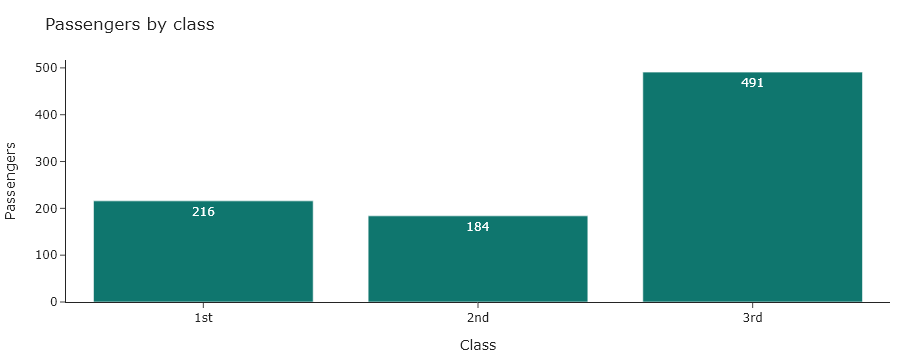

In [14]:
print(df["outcome"].value_counts(), "\nsurvival rate:", round(df["survived"].mean(), 3))
titled(ch.count_bar(df, "class"), "Passengers by class")

342 of 891 passengers survived (38%). More than half of the passengers (491) travelled in third class.

count    714.0
mean      29.7
std       14.5
min        0.4
25%       20.1
50%       28.0
75%       38.0
max       80.0
Name: age, dtype: float64


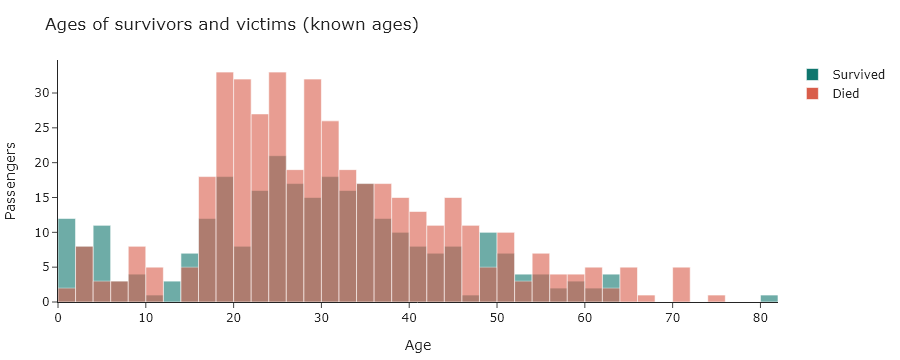

In [15]:
print(df.loc[df["age_known"], "age"].describe().round(1))
titled(ch.age_hist(df), "Ages of survivors and victims (known ages)")

The known ages run from a few months to 80, with a median of 28: a young ship. The survivors' histogram rises above the victims' only at the very left, among small children.

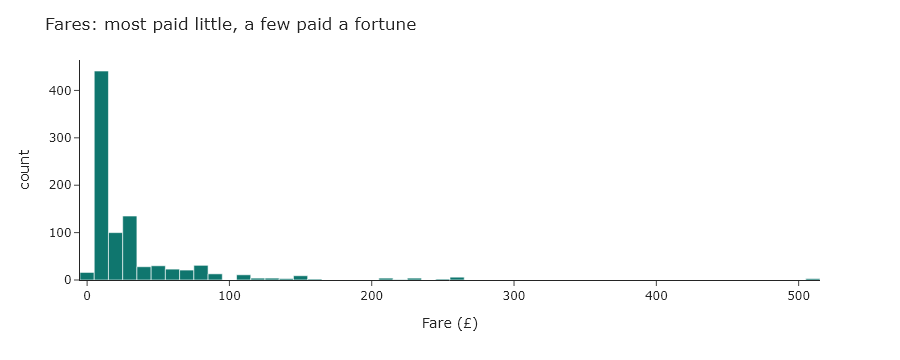

In [16]:
titled(px.histogram(df, x="fare", nbins=60), "Fares: most paid little, a few paid a fortune")

The fare is strongly right-skewed (skew 4.79): the median is £14.45 but the mean £32.20, pulled up by the first-class suites.

---
## 6. Bivariate analysis

### 6.1 Sex and class (Q2)

      sex  survived  passengers
0  female  0.742038         314
1    male  0.188908         577


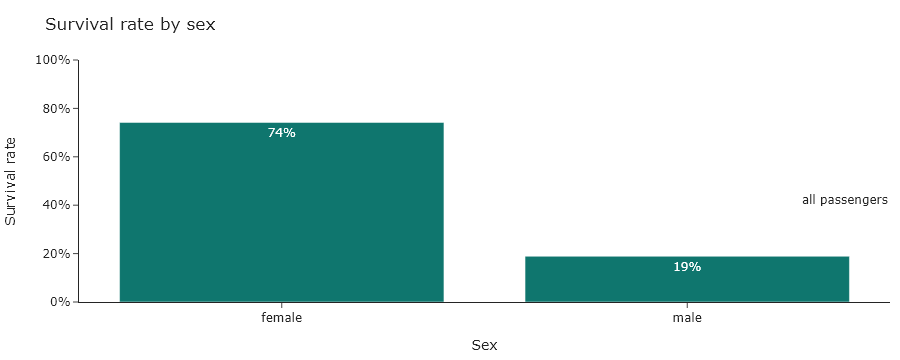

In [17]:
print(ch.rates(df, "sex"))
fig = titled(ch.rate_bar(df, "sex"), "Survival rate by sex")
save(fig, "sex.png")
fig

  class  survived  passengers
0   1st  0.629630         216
1   2nd  0.472826         184
2   3rd  0.242363         491

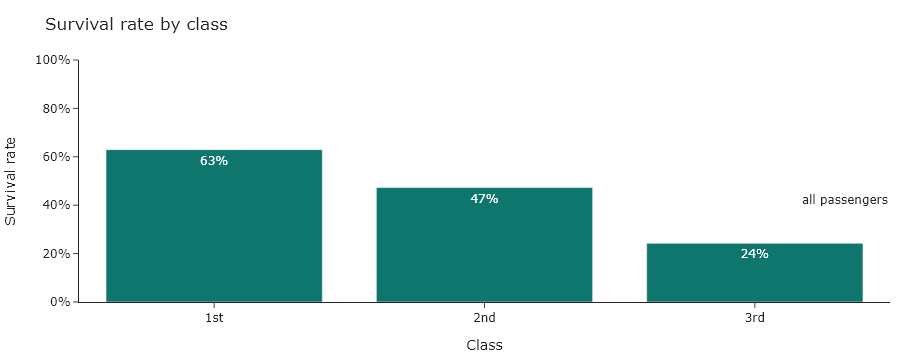

In [18]:
print(ch.rates(df, "class"))
titled(ch.rate_bar(df, "class"), "Survival rate by class")

The biggest split in the data: **74% of women survived, 19% of men**. Class matters too: 63% in first class, 47% in second, 24% in third.

### 6.2 Age and titles (Q3)

       age_group  survived  passengers
0   Child (0-12)  0.575342          73
1   Teen (13-17)  0.477273          44
2  Adult (18-59)  0.363636         748
3   Senior (60+)  0.269231          26
children 0-12 with a known age: 0.58


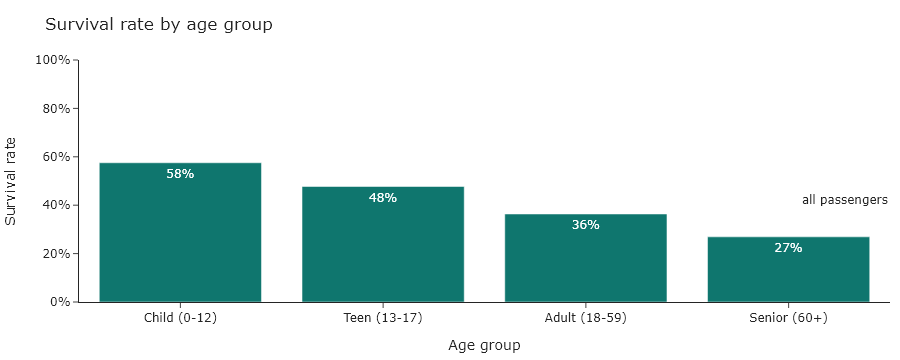

In [19]:
print(ch.rates(df, "age_group"))
print("children 0-12 with a known age:", round(df.loc[df["age_known"] & (df["age"] <= 12), "survived"].mean(), 3))
titled(ch.rate_bar(df, "age_group"), "Survival rate by age group")

    title  survived  passengers
0      Mr  0.156673         517
1     Mrs  0.793651         126
2    Miss  0.702703         185
3  Master  0.575000          40
4    Rare  0.347826          23


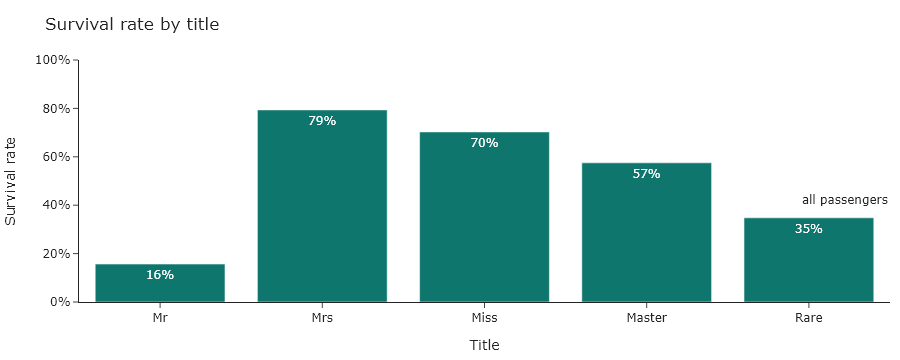

In [20]:
print(ch.rates(df, "title"))
titled(ch.rate_bar(df, "title"), "Survival rate by title")

Children (0–12) survived more often than adults, but far from all of them: about 58%. The titles sharpen the picture: Mrs 79%, Miss 70%, Master (boys) 57%, Mr only 16%. An adult man was the least likely passenger to survive.

### 6.3 Family (Q4)

  family  survived  passengers
0  Alone  0.303538         537
1    2-4  0.578767         292
2     5+  0.161290          62


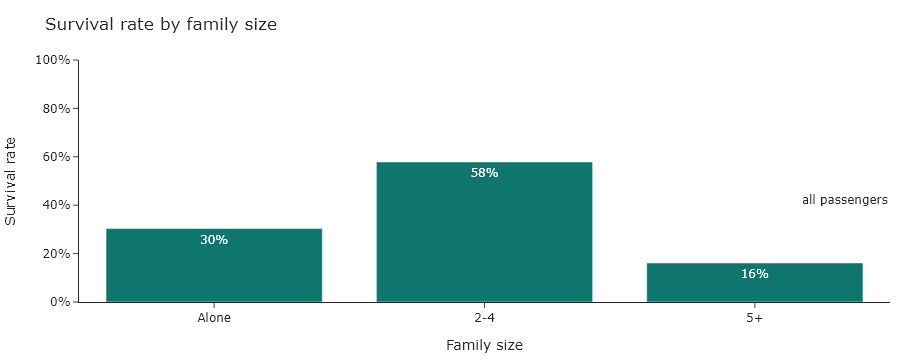

In [21]:
print(ch.rates(df, "family"))
titled(ch.rate_bar(df, "family"), "Survival rate by family size")

Small families did best (58%); passengers alone (30%) and large families of 5 or more (16%) did worst. 77% of the passengers travelling alone were men, which explains much of that low rate; large families were mostly in third class.

### 6.4 Port (Q5)

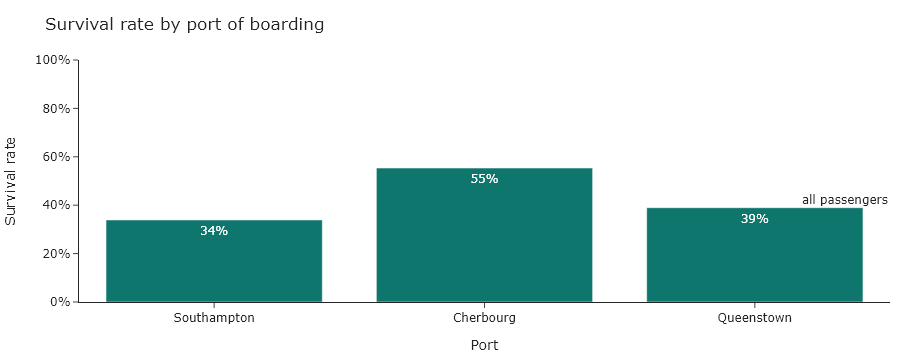

In [22]:
titled(ch.rate_bar(df, "port"), "Survival rate by port of boarding")

Cherbourg passengers survived far more often (55%) than those from Southampton (34%). A port cannot save anyone, so something else must differ between the ports: Section 7.2.

### 6.5 Fare (Q6)

r(fare, survived): 0.26


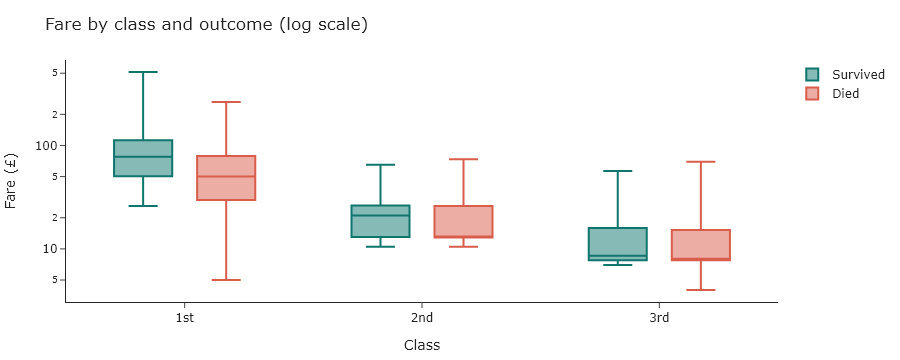

In [23]:
print("r(fare, survived):", round(df["fare"].corr(df["survived"]), 2))
titled(ch.fare_box(df), "Fare by class and outcome (log scale)")

Fare and survival are only weakly correlated (r = 0.26), and most of that link is the class. Inside first class, survivors paid much more (median £78 against £45), probably for better cabins higher in the ship; in third class the medians are almost equal (£8.50 against £8).

---
## 7. Multivariate analysis

### 7.1 Sex and class together

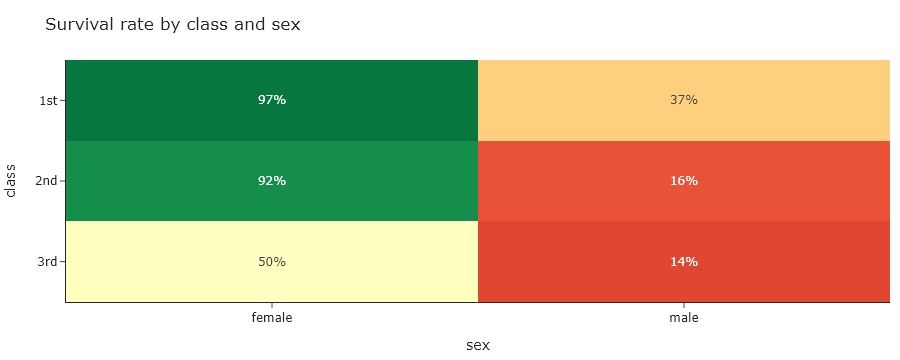

In [24]:
fig = titled(ch.rate_heatmap(df, "class", "sex"), "Survival rate by class and sex")
save(fig, "class_sex.png")
fig

Sex dominates, class sets the level. Almost every woman in first and second class survived (97% and 92%), but only half of the women in third class. A first-class man (37%) did worse than any group of women, and second- and third-class men were close (16% and 14%).

In [25]:
df[df["title"] == "Master"].groupby("class")["survived"].agg(["mean", "size"]).round(3)

,mean,size
class,,
1st,1.000,3
2nd,1.000,9
3rd,0.393,28


The same holds for boys: all 12 boys in first and second class survived, against 39% of the 28 in third class. "Women and children first" held mostly for those near the boats; third-class cabins were deep in the ship, far from the lifeboat deck.

### 7.2 Why Cherbourg? (Q5)

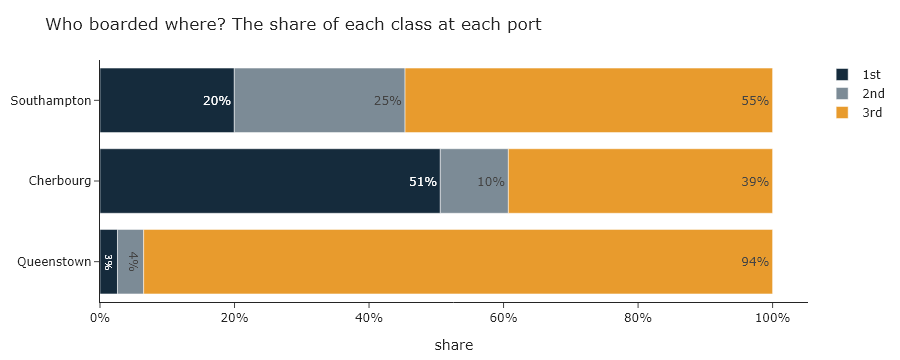

In [26]:
fig = titled(ch.port_mix(df), "Who boarded where? The share of each class at each port")
save(fig, "port_mix.png")
fig

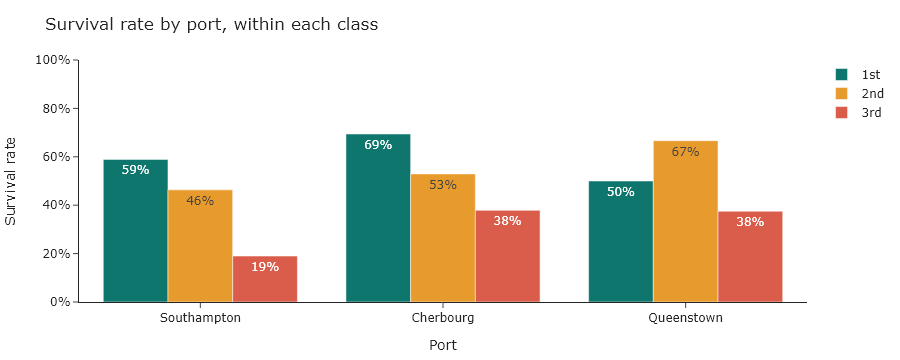

In [27]:
titled(ch.rate_by_two(df, "port", "class"), "Survival rate by port, within each class")

Half of the Cherbourg passengers travelled first class (51%), against 20% from Southampton, and Queenstown was almost entirely third class (94%). Within first and second class the gap shrinks (69% against 59%, 53% against 46%), so **most of Cherbourg's advantage is its class mix**, a group effect: the same trap as an overall correlation that hides what happens inside groups. Not all of it, though: in third class, Cherbourg passengers still survived twice as often as those from Southampton (38% against 19%). Cherbourg also had more women (44% against 32%); the data cannot say more about the rest.

---
## 8. Answers

| # | Answer |
|---|---|
| Q1 | 342 of 891 passengers survived (38%). |
| Q2 | Sex decided most: 74% of women survived, 19% of men. Class set the level: 63% in first class, 24% in third; 97% of first-class women against 14% of third-class men. |
| Q3 | Partly: about 58% of children (0–12) survived; all 12 boys in first and second class, but 39% in third. |
| Q4 | Small families (2–4 people) did best (58%); passengers alone (30%) and large families (16%) did worst. |
| Q5 | Mostly not: half of Cherbourg's passengers were first class (51%); the gap shrinks within first and second class, but in third class Cherbourg still did better (38% against 19%). |
| Q6 | Mostly through the class (r = 0.26 overall); within first class survivors paid more (median £78 against £45), within third class there is no difference. |

---
## 9. Conclusion and limitations

**Findings**
1. "Women and children first" is visible in the data: sex is the strongest single factor.
2. Class decided how well that rule worked: first- and second-class women and children almost all survived; in third class, half of the women and most of the boys died.
3. Most of the apparent effects of the port and the fare are effects of class.

**Limitations**
- 891 of about 1,300 passengers, and no crew: the full picture may differ.
- 177 ages are estimated from titles; age results use the known ages where it matters.
- Small groups (rare titles, large families, children in some classes) give unstable rates.
- The data says nothing about where each passenger was when the ship hit the iceberg, which probably mattered a lot.

The cleaned table (`data/titanic_clean.csv`) feeds the interactive dashboard in this folder.